In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv('Chi-square Analysis Data_Final.csv', low_memory=False)

# List of variables to cross-tabulate with country
variables = ['gender', 'age', 'residenceType', 'wealthquintile', 
             'schlat', 'curmar', 'work12mo']

# Create empty list to store results
all_tables = []

for var in variables:
    if var in df.columns:
        # Create crosstab with counts (no margins initially)
        ct = pd.crosstab(df[var], df['country'])
        
        # Add Overall column manually
        ct['Overall'] = ct.sum(axis=1)
        
        # Create crosstab with percentages
        ct_pct = pd.crosstab(df[var], df['country'], normalize='columns') * 100
        
        # Calculate overall percentages
        overall_pct = (ct['Overall'] / ct['Overall'].sum()) * 100
        
        # Combine counts and percentages
        result = pd.DataFrame(index=ct.index)
        
        for col in ct.columns:
            if col == 'Overall':
                for idx in ct.index:
                    count = ct.loc[idx, col]
                    pct = overall_pct.loc[idx]
                    result.loc[idx, col] = f"{count} ({pct:.0f}%)"
            else:
                for idx in ct.index:
                    count = ct.loc[idx, col]
                    pct = ct_pct.loc[idx, col]
                    result.loc[idx, col] = f"{count} ({pct:.0f}%)"
        
        # Add variable name as a column
        result.insert(0, 'Variable', var)
        result.reset_index(inplace=True)
        result.rename(columns={result.columns[1]: 'Category'}, inplace=True)
        
        all_tables.append(result)

# Combine all tables
final_table = pd.concat(all_tables, ignore_index=True)

# Display
print("\n" + "="*150)
print("SOCIODEMOGRAPHIC CHARACTERISTICS OF STUDY SAMPLE")
print("="*150)
print(final_table.to_string(index=False))

# Save
#final_table.to_csv('sociodemographic_table.csv', index=False)
final_table.to_excel('sociodemographic_table.xlsx', index=False)

#Sample size info
print("\n" + "="*80)
print("SAMPLE SIZE SUMMARY")
print("="*80)
print(f"Total sample size: {len(df)}")
print(f"\nBy country:")
sample_by_country = df['country'].value_counts().sort_values(ascending=False)
print(sample_by_country)
print(f"\nHighest: {sample_by_country.idxmax()} (N={sample_by_country.max()})")
print(f"Lowest: {sample_by_country.idxmin()} (N={sample_by_country.min()})")


SOCIODEMOGRAPHIC CHARACTERISTICS OF STUDY SAMPLE
gender       Category Cameroon Eswatini  Ethiopia   Lesotho   Malawi  Tanzania    Uganda    Zambia Zimbabwe    Overall         age residenceType wealthquintile schlat             curmar work12mo
Female         gender 64 (80%) 64 (69%)  36 (86%)  94 (63%) 67 (63%) 171 (67%) 151 (65%) 100 (70%) 53 (60%)  800 (67%)         NaN           NaN            NaN    NaN                NaN      NaN
  Male         gender 16 (20%) 29 (31%)   6 (14%)  56 (37%) 40 (37%)  83 (33%)  83 (35%)  43 (30%) 35 (40%)  391 (33%)         NaN           NaN            NaN    NaN                NaN      NaN
   NaN            age 13 (16%) 33 (35%)   7 (17%)  26 (17%) 17 (16%)  34 (13%)  49 (21%)  31 (22%) 14 (16%)  224 (19%) 15–24 years           NaN            NaN    NaN                NaN      NaN
   NaN            age 59 (74%) 54 (58%)  33 (79%) 111 (74%) 80 (75%) 175 (69%) 154 (66%) 105 (73%) 65 (74%)  836 (70%) 25–49 years           NaN            NaN    NaN    

HIVDR Proportion:
HIVDR_presence
No     52.057095
Yes    47.942905
Name: proportion, dtype: float64

Total participants: 1191


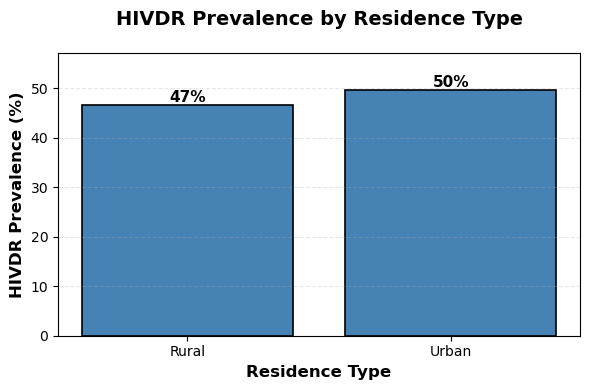


HIVDR Prevalence by Residence Type:
  residenceType  HIVDR_prevalence
0         Rural         46.617647
1         Urban         49.706458


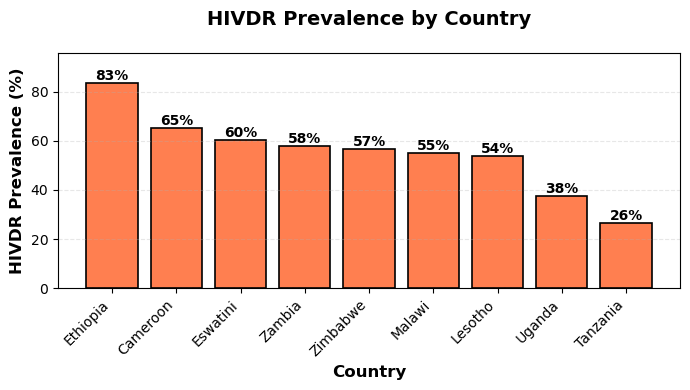


HIVDR Prevalence by Country:
    country  HIVDR_prevalence
2  Ethiopia         83.333333
0  Cameroon         65.000000
1  Eswatini         60.215054
7    Zambia         58.041958
8  Zimbabwe         56.818182
4    Malawi         55.140187
3   Lesotho         54.000000
6    Uganda         37.606838
5  Tanzania         26.377953
HIVDR Prevalence by Gender:
   gender  HIVDR_prevalence
0  Female         49.250000
1    Male         45.268542


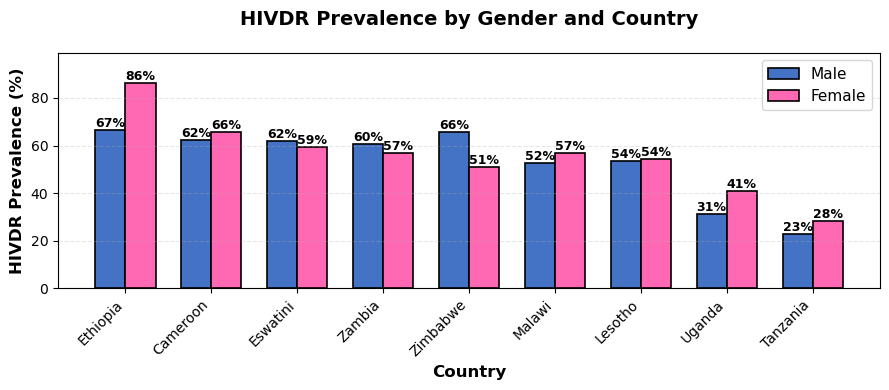


HIVDR Prevalence by Gender and Country:
gender   country     Female       Male
0       Ethiopia  86.111111  66.666667
1       Cameroon  65.625000  62.500000
2       Eswatini  59.375000  62.068966
3         Zambia  57.000000  60.465116
4       Zimbabwe  50.943396  65.714286
5         Malawi  56.716418  52.500000
6        Lesotho  54.255319  53.571429
7         Uganda  41.059603  31.325301
8       Tanzania  28.070175  22.891566


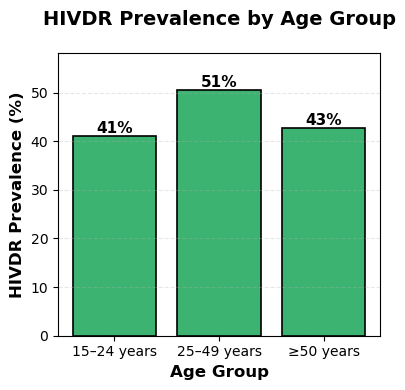


HIVDR Prevalence by Age Group:
           age  HIVDR_prevalence
0  15–24 years         41.071429
1  25–49 years         50.598086
2    ≥50 years         42.748092

All visualizations have been created and saved successfully!


In [3]:
# Load the data
df = pd.read_csv('Chi-square Analysis Data_Final.csv', low_memory=False)

# Computing HIVDR proportion
hivdr_proportion = df['HIVDR_presence'].value_counts(normalize=True) * 100
print("HIVDR Proportion:")
print(hivdr_proportion)
print(f"\nTotal participants: {len(df)}")

# Visualizing HIVDR prevalence by residence type
prevalence_residence = df.groupby('residenceType')['HIVDR_presence'].apply(
    lambda x: (x == 'Yes').sum() / len(x) * 100
).reset_index()
prevalence_residence.columns = ['residenceType', 'HIVDR_prevalence']
prevalence_residence = prevalence_residence.sort_values('residenceType')
# Creating the bar graph
plt.figure(figsize=(6, 4))
bars = plt.bar(prevalence_residence['residenceType'], 
               prevalence_residence['HIVDR_prevalence'],
               color='steelblue', 
               edgecolor='black',
               linewidth=1.2)
# Adding value labels on the bars
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height,
             f'{height:.0f}%',
             ha='center', va='bottom', fontsize=11, fontweight='bold')

plt.xlabel('Residence Type', fontsize=12, fontweight='bold')
plt.ylabel('HIVDR Prevalence (%)', fontsize=12, fontweight='bold')
plt.title('HIVDR Prevalence by Residence Type', fontsize=14, fontweight='bold', pad=20)
plt.ylim(0, max(prevalence_residence['HIVDR_prevalence']) * 1.15)
plt.grid(axis='y', alpha=0.3, linestyle='--')
plt.tight_layout()
#plt.savefig('hivdr_by_residence.png', dpi=300, bbox_inches='tight')
plt.show()
print("\nHIVDR Prevalence by Residence Type:")
print(prevalence_residence)

# Visualizing HIVDR prevalence by country
prevalence_country = df.groupby('country')['HIVDR_presence'].apply(
    lambda x: (x == 'Yes').sum() / len(x) * 100
).reset_index()
prevalence_country.columns = ['country', 'HIVDR_prevalence']
prevalence_country = prevalence_country.sort_values('HIVDR_prevalence', ascending=False)
# Creating the bar graph
plt.figure(figsize=(7, 4))
bars = plt.bar(prevalence_country['country'], 
               prevalence_country['HIVDR_prevalence'],
               color='coral', 
               edgecolor='black',
               linewidth=1.2)
# Adding value labels on the bars
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height,
             f'{height:.0f}%',
             ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.xlabel('Country', fontsize=12, fontweight='bold')
plt.ylabel('HIVDR Prevalence (%)', fontsize=12, fontweight='bold')
plt.title('HIVDR Prevalence by Country', fontsize=14, fontweight='bold', pad=20)
plt.xticks(rotation=45, ha='right')
plt.ylim(0, max(prevalence_country['HIVDR_prevalence']) * 1.15)
plt.grid(axis='y', alpha=0.3, linestyle='--')
plt.tight_layout()
#plt.savefig('hivdr_by_country.png', dpi=300, bbox_inches='tight')
plt.show()
print("\nHIVDR Prevalence by Country:")
print(prevalence_country)

# Calculating HIVDR prevalence by gender
prevalence_gender = df.groupby('gender')['HIVDR_presence'].apply(
    lambda x: (x == 'Yes').sum() / len(x) * 100
).reset_index()
prevalence_gender.columns = ['gender', 'HIVDR_prevalence']
print("HIVDR Prevalence by Gender:")
print(prevalence_gender)

# Visualizing HIVDR prevalence by gender and country 
prevalence_gender_country = df.groupby(['country', 'gender'])['HIVDR_presence'].apply(
    lambda x: (x == 'Yes').sum() / len(x) * 100
).reset_index()
prevalence_gender_country.columns = ['country', 'gender', 'HIVDR_prevalence']
prevalence_pivot = prevalence_gender_country.pivot(index='country', 
                                                    columns='gender', 
                                                    values='HIVDR_prevalence').reset_index()
country_order = prevalence_country['country'].tolist()
prevalence_pivot = prevalence_pivot.set_index('country').loc[country_order].reset_index()
# Creating the grouped bar chart
x = np.arange(len(prevalence_pivot))
width = 0.35
fig, ax = plt.subplots(figsize=(9, 4))
bars1 = ax.bar(x - width/2, prevalence_pivot['Male'], width, 
               label='Male', color='#4472C4', edgecolor='black', linewidth=1.2)
bars2 = ax.bar(x + width/2, prevalence_pivot['Female'], width, 
               label='Female', color='#FF69B4', edgecolor='black', linewidth=1.2)
# Adding value labels on the bars
for bars in [bars1, bars2]:
    for bar in bars:
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2., height,
                f'{height:.0f}%',
                ha='center', va='bottom', fontsize=9, fontweight='bold')

ax.set_xlabel('Country', fontsize=12, fontweight='bold')
ax.set_ylabel('HIVDR Prevalence (%)', fontsize=12, fontweight='bold')
ax.set_title('HIVDR Prevalence by Gender and Country', fontsize=14, fontweight='bold', pad=20)
ax.set_xticks(x)
ax.set_xticklabels(prevalence_pivot['country'], rotation=45, ha='right')
ax.legend(fontsize=11, loc='upper right')
ax.grid(axis='y', alpha=0.3, linestyle='--')
ax.set_ylim(0, max(prevalence_pivot[['Male', 'Female']].max()) * 1.15)

plt.tight_layout()
#plt.savefig('hivdr_by_gender_country.png', dpi=300, bbox_inches='tight')
plt.show()
print("\nHIVDR Prevalence by Gender and Country:")
print(prevalence_pivot)

# Visualizing HIVDR prevalence by age groups
prevalence_age = df.groupby('age')['HIVDR_presence'].apply(
    lambda x: (x == 'Yes').sum() / len(x) * 100
).reset_index()
prevalence_age.columns = ['age', 'HIVDR_prevalence']
age_order = ['15–24 years', '25–49 years', '≥50 years']
prevalence_age['age'] = pd.Categorical(prevalence_age['age'], categories=age_order, ordered=True)
prevalence_age = prevalence_age.sort_values('age')
# Creating the bar chart
plt.figure(figsize=(4, 4))
bars = plt.bar(prevalence_age['age'], 
               prevalence_age['HIVDR_prevalence'],
               color='mediumseagreen',  # Single color
               edgecolor='black',
               linewidth=1.2)

# Add value labels on bars
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height,
             f'{height:.0f}%',
             ha='center', va='bottom', fontsize=11, fontweight='bold')

plt.xlabel('Age Group', fontsize=12, fontweight='bold')
plt.ylabel('HIVDR Prevalence (%)', fontsize=12, fontweight='bold')
plt.title('HIVDR Prevalence by Age Group', fontsize=14, fontweight='bold', pad=20)
plt.xticks(rotation=0)
plt.ylim(0, max(prevalence_age['HIVDR_prevalence']) * 1.15)
plt.grid(axis='y', alpha=0.3, linestyle='--')
plt.tight_layout()
#plt.savefig('hivdr_by_age.png', dpi=300, bbox_inches='tight')
plt.show()
print("\nHIVDR Prevalence by Age Group:")
print(prevalence_age)

print("\n" + "="*70)
print("All visualizations have been created and saved successfully!")
print("="*70)